In [1]:
!pip install patchify --no-deps
!pip install --upgrade numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 36.9 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
patchify 0.2.3 requires numpy<2,>=1, but you have numpy 2.5.4 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.


In [1]:
import os
import cv2
from PIL import Image
import numpy as np
from patchify import patchify
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from matplotlib import pyplot as plt
import random
from tensorflow.keras.utils import to_categorical

In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
!ls -lah '/content/drive/MyDrive/SatelliteImages/Semantic segmentation dataset'

total 41K
drwx------ 10 root root 4.0K Oct  1 08:03  .
drwx------  3 root root 4.0K Oct  1 08:03  ..
-rw-------  1 root root  548 Oct  1 08:02  classes.json
drwx------  2 root root 4.0K Oct  1 08:03 'Tile 1'
drwx------  2 root root 4.0K Oct  1 08:03 'Tile 2'
drwx------  2 root root 4.0K Oct  1 08:03 'Tile 3'
drwx------  2 root root 4.0K Oct  1 08:03 'Tile 4'
drwx------  2 root root 4.0K Oct  1 08:03 'Tile 5'
drwx------  2 root root 4.0K Oct  1 08:03 'Tile 6'
drwx------  2 root root 4.0K Oct  1 08:03 'Tile 7'
drwx------  2 root root 4.0K Oct  1 08:03 'Tile 8'


In [4]:
dataset_root_folder = '/content/drive/MyDrive/SatelliteImages'

In [5]:
dataset_name = "Semantic segmentation dataset"

In [6]:
image_patch_size = 256

In [7]:
minmaxscaler = MinMaxScaler()

In [8]:
image_dataset = []
mask_dataset = []

for image_type in ['images' , 'masks']:
  if image_type == 'images':
    image_extension = 'jpg'
  elif image_type == 'masks':
     image_extension = 'png'
  for tile_id in range(1,8):
    for image_id in range(1,20):
      image = cv2.imread(f'{dataset_root_folder}/{dataset_name}/Tile {tile_id}/{image_type}/image_part_00{image_id}.{image_extension}',1)
      if image is not None:
        if image_type == 'masks':
          image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        size_x = (image.shape[1]//image_patch_size)*image_patch_size
        size_y = (image.shape[0]//image_patch_size)*image_patch_size
        image = Image.fromarray(image)
        image = image.crop((0,0, size_x, size_y))
        image = np.array(image)
        patched_images = patchify(image, (image_patch_size, image_patch_size, 3), step=image_patch_size)
        for i in range(patched_images.shape[0]):
          for j in range(patched_images.shape[1]):
            if image_type == 'images':
              individual_patched_image = patched_images[i,j,:,:]
              individual_patched_image = minmaxscaler.fit_transform(individual_patched_image.reshape(-1, individual_patched_image.shape[-1])).reshape(individual_patched_image.shape)
              individual_patched_image = individual_patched_image[0]
              image_dataset.append(individual_patched_image)
            elif image_type == 'masks':
              individual_patched_mask = patched_images[i,j,:,:]
              individual_patched_mask = individual_patched_mask[0]
              mask_dataset.append(individual_patched_mask)

In [9]:
image_dataset = np.array(image_dataset)
mask_dataset = np.array(mask_dataset)

In [10]:
print(len(image_dataset))
print(len(mask_dataset))

945
945


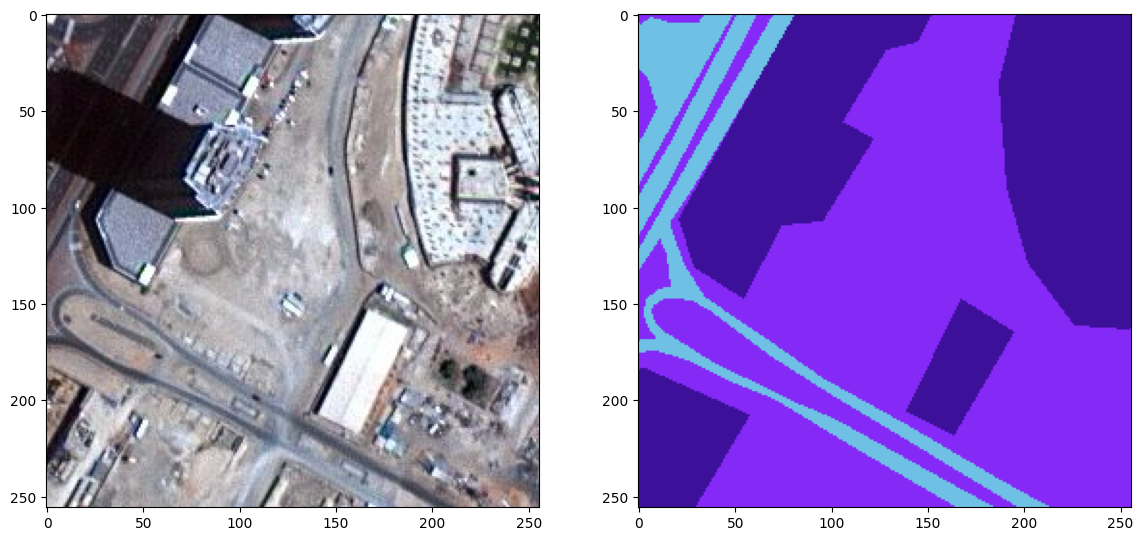

In [11]:
random_image_id = random.randint(0, len(image_dataset))

plt.figure(figsize=(14,8))
plt.subplot(121)
plt.imshow(image_dataset[random_image_id])
plt.subplot(122)
plt.imshow(mask_dataset[random_image_id])


In [12]:
class_building = '#3C1098'
class_building = class_building.lstrip('#')
class_building = np.array(tuple(int(class_building[i:i+2], 16) for i in (0,2,4)))
print(class_building)

class_land = '#8429F6'
class_land = class_land.lstrip('#')
class_land = np.array(tuple(int(class_land[i:i+2], 16) for i in (0,2,4)))
print(class_land)

class_road = '#6EC1E4'
class_road = class_road.lstrip('#')
class_road = np.array(tuple(int(class_road[i:i+2], 16) for i in (0,2,4)))
print(class_road)

class_vegetation = '#FEDD3A'
class_vegetation = class_vegetation.lstrip('#')
class_vegetation = np.array(tuple(int(class_vegetation[i:i+2], 16) for i in (0,2,4)))
print(class_vegetation)

class_water = '#E2A929'
class_water = class_water.lstrip('#')
class_water = np.array(tuple(int(class_water[i:i+2], 16) for i in (0,2,4)))
print(class_water)

class_unlabeled = '#9B9B9B'
class_unlabeled = class_unlabeled.lstrip('#')
class_unlabeled = np.array(tuple(int(class_unlabeled[i:i+2], 16) for i in (0,2,4)))
print(class_unlabeled)

[ 60  16 152]
[132  41 246]
[110 193 228]
[254 221  58]
[226 169  41]
[155 155 155]


In [13]:
label = individual_patched_mask

In [14]:
def rgb_to_label(label):
  label_segment = np.zeros(label.shape, dtype=np.uint8)
  label_segment[np.all(label == class_water, axis=-1)] = 0
  label_segment[np.all(label == class_land, axis=-1)] = 1
  label_segment[np.all(label == class_road, axis=-1)] = 2
  label_segment[np.all(label == class_building, axis=-1)] = 3
  label_segment[np.all(label == class_vegetation, axis=-1)] = 4
  label_segment[np.all(label == class_unlabeled, axis=-1)] = 5
  #print(label_segment)
  label_segment = label_segment[:,:,0]
  #print(label_segment)
  return label_segment

In [15]:
labels = []
for i in range(mask_dataset.shape[0]):
  label = rgb_to_label(mask_dataset[i])
  labels.append(label)

In [16]:
labels = np.array(labels)
labels = np.expand_dims(labels, axis=3)

In [17]:
np.unique(labels)

array([0, 1, 2, 3, 4, 5], dtype=uint8)

In [18]:
print("Total unique labels based on masks: ", format(np.unique(labels)))

Total unique labels based on masks:  [0 1 2 3 4 5]


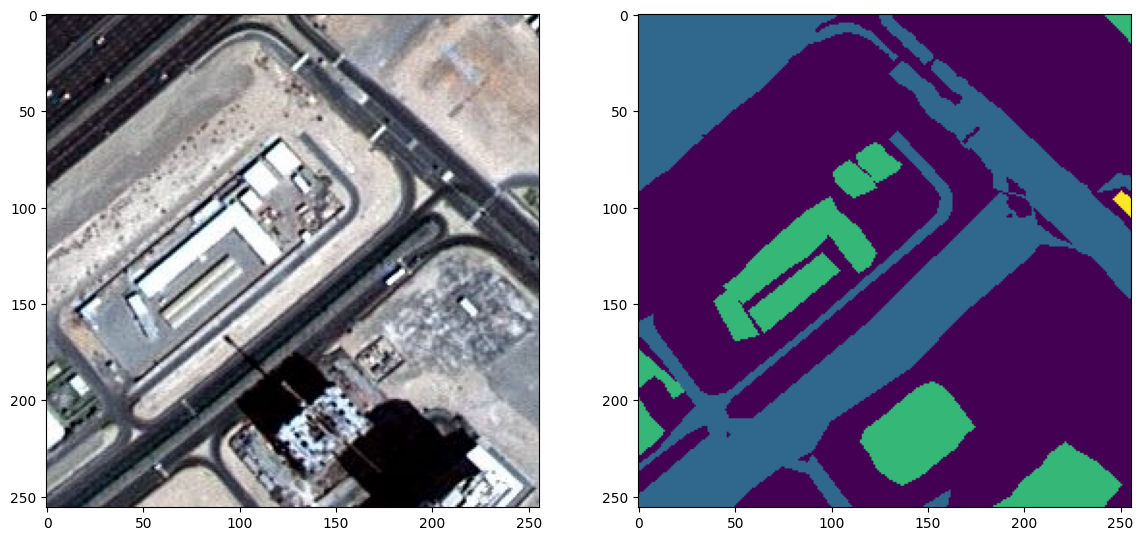

In [19]:
random_image_id = random.randint(0, len(image_dataset))

plt.figure(figsize=(14,8))
plt.subplot(121)
plt.imshow(image_dataset[random_image_id])
plt.subplot(122)
plt.imshow(labels[random_image_id][:,:,0])


In [20]:
total_classes = len(np.unique(labels))
print(total_classes)

6


In [21]:
labels_categorical_dataset = to_categorical(labels, num_classes=total_classes)

In [22]:
master_trianing_dataset = image_dataset

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
X_train, X_test, Y_train, Y_test = train_test_split(master_trianing_dataset, labels_categorical_dataset, test_size = 0.15, random_state = 100)

In [25]:
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)


(803, 256, 256, 3)
(142, 256, 256, 3)
(803, 256, 256, 6)
(142, 256, 256, 6)


In [26]:
image_height = X_train.shape[1]
image_width = X_train.shape[2]
image_channels = X_train.shape[3]
total_classes = Y_train.shape[3]

In [27]:
print(image_height)
print(image_width)
print(image_channels)
print(total_classes)

256
256
3
6


In [28]:
!pip install -U segmentation-models

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [segmentation-models]


In [29]:
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate, Conv2DTranspose, BatchNormalization, Dropout, Lambda
from keras import backend as K

In [46]:
import tensorflow as tf

def jaccard_coef(y_true, y_pred):
    y_true_flatten = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_flatten = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    intersection = tf.reduce_sum(y_true_flatten * y_pred_flatten)
    total = tf.reduce_sum(y_true_flatten) + tf.reduce_sum(y_pred_flatten) - intersection
    return (intersection + 1.0) / (total + 1.0)

# def jaccard_coef(y_true, y_pred):
#     y_true_flatten = K.flatten(y_true)
#     y_pred_flatten = K.flatten(y_pred)
#     intersection = K.sum(y_true_flatten * y_pred_flatten)
#     final_coef_value = (intersection + 1.0) / (K.sum(y_true_flatten) + K.sum(y_pred_flatten) - intersection + 1.0)
#     return final_coef_value

In [31]:
def multi_unet_model(n_classes=5, image_height=256, image_width=256, image_channels=1):

  inputs = Input((image_height, image_width, image_channels))

  source_input = inputs

  c1 = Conv2D(16, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(source_input)
  c1 = Dropout(0.2)(c1)
  c1 = Conv2D(16, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(c1)
  p1 = MaxPooling2D((2,2))(c1)

  c2 = Conv2D(32, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(p1)
  c2 = Dropout(0.2)(c2)
  c2 = Conv2D(32, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(c2)
  p2 = MaxPooling2D((2,2))(c2)

  c3 = Conv2D(64, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(p2)
  c3 = Dropout(0.2)(c3)
  c3 = Conv2D(64, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(c3)
  p3 = MaxPooling2D((2,2))(c3)

  c4 = Conv2D(128, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(p3)
  c4 = Dropout(0.2)(c4)
  c4 = Conv2D(128, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(c4)
  p4 = MaxPooling2D((2,2))(c4)

  c5 = Conv2D(256, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(p4)
  c5 = Dropout(0.2)(c5)
  c5 = Conv2D(256, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(c5)

  u6 = Conv2DTranspose(128, (2,2), strides=(2,2), padding="same")(c5)
  u6 = concatenate([u6, c4])
  c6 = Conv2D(128, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(u6)
  c6 = Dropout(0.2)(c6)
  c6 = Conv2D(128, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(c6)

  u7 = Conv2DTranspose(64, (2,2), strides=(2,2), padding="same")(c6)
  u7 = concatenate([u7, c3])
  c7 = Conv2D(64, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(u7)
  c7 = Dropout(0.2)(c7)
  c7 = Conv2D(64, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(c7)

  u8 = Conv2DTranspose(32, (2,2), strides=(2,2), padding="same")(c7)
  u8 = concatenate([u8, c2])
  c8 = Conv2D(32, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(u8)
  c8 = Dropout(0.2)(c8)
  c8 = Conv2D(32, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(c8)

  u9 = Conv2DTranspose(16, (2,2), strides=(2,2), padding="same")(c8)
  u9 = concatenate([u9, c1], axis=3)
  c9 = Conv2D(16, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(u9)
  c9 = Dropout(0.2)(c9)
  c9 = Conv2D(16, (3,3), activation="relu", kernel_initializer="he_normal", padding="same")(c9)

  outputs = Conv2D(n_classes, (1,1), activation="softmax")(c9)

  model = Model(inputs=[inputs], outputs=[outputs])
  return model

In [47]:
metrics = ["accuracy", jaccard_coef]

In [33]:
print(image_height)
print(image_width)
print(image_channels)
print(total_classes)

256
256
3
6


In [34]:
def get_deep_learning_model():
  return multi_unet_model(n_classes=total_classes,
                          image_height=image_height,
                          image_width=image_width,
                          image_channels=image_channels)

In [35]:
import gc
import numpy as np

# 1. Ép kiểu về float32 để giảm 50% dung lượng bộ nhớ
X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)
Y_train = Y_train.astype(np.float32)
Y_test = Y_test.astype(np.float32)

# 2. Xóa các mảng trung gian không còn dùng đến
del image_dataset
del mask_dataset
del labels
del labels_categorical_dataset
del master_trianing_dataset

# 3. Thu hồi RAM hệ thống
gc.collect()

60

In [36]:
model = get_deep_learning_model()

In [37]:
weights = [1/6, 1/6, 1/6, 1/6, 1/6, 1/6]

In [38]:
!pip install tf-keras

In [39]:
import os
os.environ["SM_FRAMEWORK"] = "tf.keras"
import segmentation_models as sm

Segmentation Models: using `tf.keras` framework.


In [40]:
dice_loss = sm.losses.DiceLoss(class_weights=weights)
focal_loss = sm.losses.CategoricalFocalLoss()
total_loss = dice_loss + (1 * focal_loss)

In [41]:
import tensorflow as tf

In [42]:
tf.keras.backend.clear_session()

In [48]:
model.compile(optimizer="adam", loss=total_loss, metrics=metrics)

In [44]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        448 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256, 256,  │          0 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      2,320 │ dropout[0][0]     │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128, 128,  │          0 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │      9,248 │ dropout_1[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64, 64,    │          0 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     36,928 │ dropout_2[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32, 32,    │          0 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │    147,584 │ dropout_3[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 16,    │          0 │ conv2d_7[0][0]  

 Total params: 1,941,190 (7.41 MB)

 Trainable params: 1,941,190 (7.41 MB)

 Non-trainable params: 0 (0.00 B)

In [49]:
import tensorflow as tf

batch_size = 8  # Bạn có thể dùng 8 hoặc 16

train_dataset = tf.data.Dataset.from_tensor_slices((X_train, Y_train)).batch(batch_size).prefetch(tf.data.AUTOTUNE)
val_dataset = tf.data.Dataset.from_tensor_slices((X_test, Y_test)).batch(batch_size).prefetch(tf.data.AUTOTUNE)

model_history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=100,
    verbose=1
)

Epoch 1/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 84s 438ms/step - accuracy: 0.6187 - jaccard_coef: 0.3180 - loss: 0.9919 - val_accuracy: 0.6680 - val_jaccard_coef: 0.4102 - val_loss: 0.9760
Epoch 2/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 11s 112ms/step - accuracy: 0.6961 - jaccard_coef: 0.4234 - loss: 0.9706 - val_accuracy: 0.6923 - val_jaccard_coef: 0.4027 - val_loss: 0.9709
Epoch 3/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 12s 116ms/step - accuracy: 0.7123 - jaccard_coef: 0.4503 - loss: 0.9659 - val_accuracy: 0.6966 - val_jaccard_coef: 0.4487 - val_loss: 0.9694
Epoch 4/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 12s 115ms/step - accuracy: 0.7359 - jaccard_coef: 0.4862 - loss: 0.9595 - val_accuracy: 0.7389 - val_jaccard_coef: 0.4906 - val_loss: 0.9561
Epoch 5/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 11s 111ms/step - accuracy: 0.7504 - jaccard_coef: 0.5114 - loss: 0.9546 - val_accuracy: 0.7549 - val_jaccard_coef: 0.5141 - val_loss: 0.9513
Epoch 6/100
101/101 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - accuracy: 0.7712 - jaccard_coef:

In [ ]:
# model_history = model.fit(X_train, Y_train,
#                           validation_data=(X_test, Y_test),
#                           batch_size=4,
#                           verbose=1,
#                           epochs=100,
#                           shuffle=False
#                           )

In [50]:
history_a = model_history

In [51]:
history_a.history

{'accuracy': [0.6186887621879578,
  0.6961272954940796,
  0.712266743183136,
  0.7358647584915161,
  0.7504236102104187,
  0.7712198495864868,
  0.7836349606513977,
  0.7876842021942139,
  0.8017358183860779,
  0.804560124874115,
  0.8107747435569763,
  0.8209875822067261,
  0.8250072002410889,
  0.8282932043075562,
  0.8302628397941589,
  0.8351128101348877,
  0.8369817733764648,
  0.8391609787940979,
  0.8423188328742981,
  0.8413049578666687,
  0.8446359038352966,
  0.8487949371337891,
  0.8504762053489685,
  0.8539514541625977,
  0.8532121777534485,
  0.8549782037734985,
  0.856334388256073,
  0.8570834994316101,
  0.8573421239852905,
  0.862311840057373,
  0.8650692105293274,
  0.8653795719146729,
  0.8664042949676514,
  0.8621183037757874,
  0.8674728870391846,
  0.8641562461853027,
  0.8500244617462158,
  0.8651379942893982,
  0.8703927397727966,
  0.8736534118652344,
  0.8766777515411377,
  0.8786281943321228,
  0.8791018128395081,
  0.8791114091873169,
  0.8768275380134583,
  

Text(0, 0.5, 'Loss')

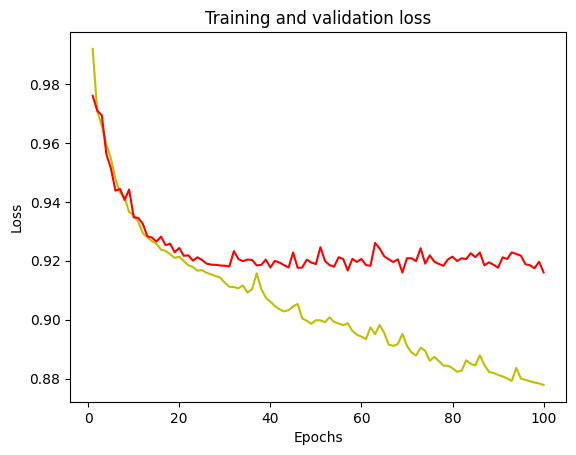

In [52]:
loss = history_a.history['loss']
val_loss = history_a.history['val_loss']
epochs = range(1, len(loss) + 1)

plt.plot(epochs, loss, 'y', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

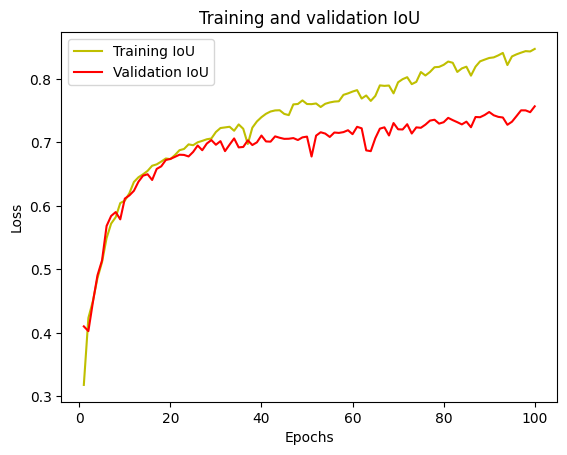

In [53]:
jaccard_coef = history_a.history['jaccard_coef']
val_jaccard_coef = history_a.history['val_jaccard_coef']
epochs = range(1, len(jaccard_coef) + 1)

plt.plot(epochs, jaccard_coef, 'y', label='Training IoU')
plt.plot(epochs, val_jaccard_coef, 'r', label='Validation IoU')
plt.title('Training and validation IoU')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [54]:
model_history.params

{'verbose': 1, 'epochs': 100, 'steps': 101}

In [55]:
y_pred = model.predict(X_test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 898ms/step


In [56]:
len(y_pred)

142

In [57]:
y_pred

array([[[[1.83351454e-03, 6.96384788e-01, 7.95878693e-02,
          2.04320058e-01, 1.66285187e-02, 1.24524382e-03],
         [4.97827190e-04, 6.31317616e-01, 4.27304693e-02,
          3.19935739e-01, 5.21363784e-03, 3.04621703e-04],
         [4.47863102e-04, 4.74959135e-01, 3.04406863e-02,
          4.89791602e-01, 4.06022836e-03, 3.00389307e-04],
         ...,
         [1.04731291e-04, 6.72628284e-02, 5.87355718e-03,
          9.24280465e-01, 2.46002735e-03, 1.82807689e-05],
         [1.93690328e-04, 8.90092328e-02, 7.09268590e-03,
          9.01205182e-01, 2.46245391e-03, 3.67907342e-05],
         [3.19983368e-03, 1.23534501e-01, 1.81530267e-02,
          8.42414260e-01, 1.18909450e-02, 8.07359349e-04]],

        [[2.77934334e-04, 7.20677674e-01, 4.47997302e-02,
          2.26211593e-01, 7.88482744e-03, 1.48206629e-04],
         [4.25893340e-05, 6.92959249e-01, 1.82615612e-02,
          2.86824137e-01, 1.88969751e-03, 2.27479995e-05],
         [3.53151918e-05, 4.90904927e-01, 1.2070

In [58]:
y_pred_argmax = np.argmax(y_pred, axis=3)

In [59]:
len(y_pred_argmax)

142

In [60]:
y_pred_argmax

array([[[1, 1, 3, ..., 3, 3, 3],
        [1, 1, 3, ..., 3, 3, 3],
        [1, 1, 3, ..., 3, 3, 3],
        ...,
        [0, 0, 0, ..., 1, 1, 1],
        [0, 0, 0, ..., 1, 1, 1],
        [0, 0, 0, ..., 1, 1, 1]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[2, 2, 2, ..., 3, 1, 1],
        [2, 2, 2, ..., 3, 1, 1],
        [2, 2, 2, ..., 3, 3, 1],
        ...,
        [1, 1, 1, ..., 2, 2, 2],
        [1, 1, 1, ..., 2, 2, 2],
        [1, 1, 1, ..., 2, 2, 2]],

       ...,

       [[1, 1, 1, ..., 1, 1, 1],
        [1, 1, 1, ..., 1, 1, 1],
        [1, 1, 1, ..., 1, 1, 1],
        ...,
        [1, 1, 1, ..., 4, 4, 4],
        [1, 1, 1, ..., 4, 4, 4],
        [1, 1, 1, ..., 4, 4, 4]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [61]:
y_test_argmax = np.argmax(Y_test, axis=3)

In [62]:
y_test_argmax

array([[[3, 3, 3, ..., 1, 1, 1],
        [3, 3, 3, ..., 3, 3, 3],
        [3, 3, 3, ..., 3, 3, 3],
        ...,
        [0, 0, 0, ..., 1, 1, 1],
        [0, 0, 0, ..., 1, 1, 1],
        [0, 0, 0, ..., 1, 1, 1]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[2, 2, 2, ..., 1, 1, 1],
        [2, 2, 2, ..., 1, 1, 1],
        [2, 2, 2, ..., 1, 1, 1],
        ...,
        [2, 2, 2, ..., 0, 0, 0],
        [2, 2, 2, ..., 0, 0, 0],
        [2, 2, 1, ..., 0, 0, 0]],

       ...,

       [[1, 1, 1, ..., 1, 1, 1],
        [1, 1, 1, ..., 1, 1, 1],
        [1, 1, 1, ..., 1, 1, 1],
        ...,
        [1, 1, 1, ..., 0, 0, 0],
        [1, 1, 1, ..., 0, 0, 0],
        [1, 1, 1, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 

In [74]:
test_image_number = random.randint(0, len(X_test))
test_image = X_test[test_image_number]
ground_truth_image = y_test_argmax[test_image_number]

test_image_input = np.expand_dims(test_image, axis=0)

prediction = model.predict(test_image_input)
predicted_image = np.argmax(prediction, axis=3)[0,:,:]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


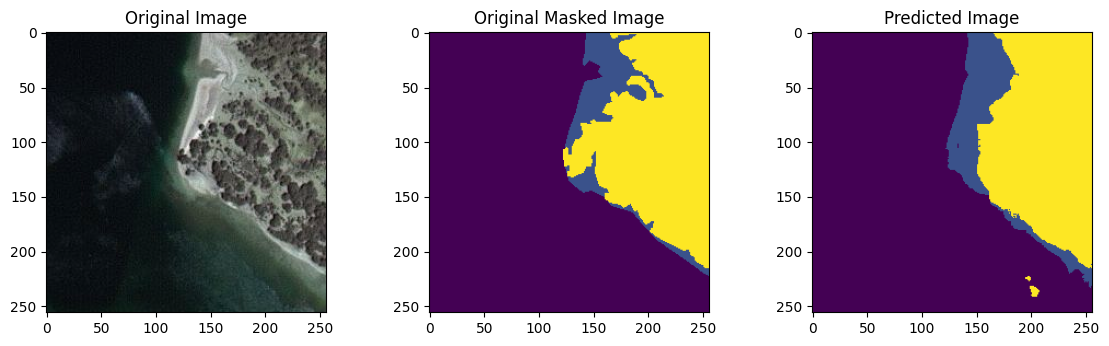

In [75]:
plt.figure(figsize=(14,8))

plt.subplot(231)
plt.title('Original Image')
plt.imshow(test_image)

plt.subplot(232)
plt.title('Original Masked Image')
plt.imshow(ground_truth_image)

plt.subplot(233)
plt.title('Predicted Image')
plt.imshow(predicted_image)

plt.show()

In [78]:
model.save("satellie_segmentation_full.h5")

In [79]:
!ls -lah

total 23M
drwxr-xr-x 1 root root 4.0K Oct 28 17:40 .
drwxr-xr-x 1 root root 4.0K Oct 28 16:30 ..
drwxr-xr-x 4 root root 4.0K Oct 21 13:28 .config
drwx------ 6 root root 4.0K Oct 28 16:39 drive
drwxr-xr-x 1 root root 4.0K Oct 21 13:28 sample_data
-rw-r--r-- 1 root root  23M Oct 28 17:40 satellie_segmentation_full.h5
